# RTM Inter-area Connectivity

This notebook connects one RTM excitatory cell per brain area using the project's FLN matrix. V4 receives a brief external pulse. We compare an uncoupled control with a condition where RTM spikes travel along FLN-weighted projections.

This first prototype has one RTM cell per area, no WB cells in this notebook, and no propagation delays. FLN sets relative projection weights; one global conductance parameter sets their overall effect.

## Step 1: Load the project data

We use the same connectivity file and area ordering as the project's large-scale model. Matrix rows and columns must match the RTM cells' area order.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data").is_dir() and (p / "template_kwargs.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Start Jupyter from the project root or one of its subdirectories.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from brian2 import (
    NeuronGroup, Synapses, StateMonitor, SpikeMonitor, Network, TimedArray,
    ms, mV, uA, cm, uF, msiemens, siemens, Hz,
)
from template_kwargs import template_kwargs

connectivity_path = project_root / "data" / template_kwargs["connectivity_file"]
with open(connectivity_path, "rb") as f:
    anatomy = np.load(f, allow_pickle=True, encoding="bytes")

area_labels = [
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in anatomy[b"area_list"]
]
raw_fln = np.asarray(anatomy[b"fln"], dtype=float)
n_areas = len(area_labels)

assert raw_fln.shape == (n_areas, n_areas), (
    f"Expected an {n_areas}x{n_areas} FLN matrix; got {raw_fln.shape}."
)
assert len(set(area_labels)) == n_areas, "Area names must be unique."
assert "V4" in area_labels, "V4 is not present in the connectivity data."

print("Connectivity file:", connectivity_path.name)
print("Number of areas:", n_areas)
print("FLN matrix shape:", raw_fln.shape)
print("V4 index:", area_labels.index("V4"))
print("First 10 areas:", area_labels[:10])

Connectivity file: subgraph_data40.pkl
Number of areas: 40
FLN matrix shape: (40, 40)
V4 index: 2
First 10 areas: ['V1', 'V2', 'V4', '1', '3', 'MT', 'V6', 'DP', 'TEO', '8m']


## Step 2: Prepare the FLN weights

The project uses FLN[i, j] for a projection from source area j to target area i. It transforms each entry as fln_a times FLN to the power fln_b, then normalizes each target row so its incoming weights sum to one.

In [2]:
fln_a = float(template_kwargs["fln_a"])
fln_b = float(template_kwargs["fln_b"])
scaled_fln = fln_a * np.clip(raw_fln, 0.0, None) ** fln_b

incoming_totals = np.nansum(scaled_fln, axis=1, keepdims=True)
fln_weights = np.divide(
    scaled_fln,
    incoming_totals,
    out=np.zeros_like(scaled_fln),
    where=incoming_totals > 0,
)
fln_weights = np.nan_to_num(fln_weights)

print("Direction: source area j -> target area i")
print("Nonzero directed projections:", int(np.count_nonzero(fln_weights)))
print(
    "Incoming weight sums (min, max):",
    float(fln_weights.sum(axis=1).min()),
    float(fln_weights.sum(axis=1).max()),
)
print("Nonzero self-connections:", int(np.count_nonzero(np.diag(fln_weights))))

Direction: source area j -> target area i
Nonzero directed projections: 999
Incoming weight sums (min, max): 0.9999999999999998 1.0000000000000002
Nonzero self-connections: 0


## Step 3: Choose the simulation settings

The same V4 current pulse is used in both conditions. link_conductance controls the overall strength of inter-area input. Each source spike adds this conductance multiplied by its source-to-target FLN weight. Its value is provisional.

In [3]:
run_duration = 300 * ms
dt = 0.01 * ms
base_current = 0.0                 # microampere/cm^2
pulse_current = 0.24               # microampere/cm^2 (provisional)
pulse_on = 100 * ms
pulse_off = 150 * ms
link_conductance = 0.1 * msiemens / cm**2
link_decay = 5 * ms
stimulated_area = "V4"

print("Duration:", run_duration / ms, "ms")
print("Time step:", dt / ms, "ms")
print("Stimulus area:", stimulated_area)
print("Stimulus window:", pulse_on / ms, "to", pulse_off / ms, "ms")
print("Inter-area conductance scale:", link_conductance / (msiemens / cm**2), "mS/cm^2")

Duration: 300.0 ms
Time step: 0.01 ms
Stimulus area: V4
Stimulus window: 100.0 to 150.0 ms
Inter-area conductance scale: 0.1 mS/cm^2


## Step 4: Define one RTM cell per area

Each RTM cell follows the same membrane and gating equations. The added g_long variable represents excitatory conductance arriving from other areas. It decays over time and produces inward current because its reversal potential is 0 mV.

The uncoupled control has the same cells, initial state, and V4 pulse, but no inter-area synapses.

In [4]:
rtm_equations = "\n".join([
    "dv/dt = (I_app + I_long - gNa*m_inf**3*h*(v-vNa) - gK*n**4*(v-vK) - gL*(v-vL))/C_m : volt",
    "dh/dt = alpha_h*(1-h)-beta_h*h : 1",
    "dn/dt = alpha_n*(1-n)-beta_n*n : 1",
    "alpha_m = (1.28/ms)/exprel(-(v/mV+54)/4) : Hz",
    "beta_m = (1.4/ms)/exprel((v/mV+27)/5) : Hz",
    "alpha_h = (0.128/ms)*exp(-(v/mV+50)/18) : Hz",
    "beta_h = (4/ms)/(1+exp(-(v/mV+27)/5)) : Hz",
    "alpha_n = (0.16/ms)/exprel(-(v/mV+52)/5) : Hz",
    "beta_n = (0.5/ms)*exp(-(v/mV+57)/40) : Hz",
    "m_inf = alpha_m/(alpha_m+beta_m) : 1",
    "I_app = input_current(t, area_index) : amp/meter**2",
    "I_long = g_long*(E_exc-v) : amp/meter**2",
    "dg_long/dt = -g_long/tau_long : siemens/meter**2",
    "area_index : integer (constant)",
])
print(rtm_equations)

dv/dt = (I_app + I_long - gNa*m_inf**3*h*(v-vNa) - gK*n**4*(v-vK) - gL*(v-vL))/C_m : volt
dh/dt = alpha_h*(1-h)-beta_h*h : 1
dn/dt = alpha_n*(1-n)-beta_n*n : 1
alpha_m = (1.28/ms)/exprel(-(v/mV+54)/4) : Hz
beta_m = (1.4/ms)/exprel((v/mV+27)/5) : Hz
alpha_h = (0.128/ms)*exp(-(v/mV+50)/18) : Hz
beta_h = (4/ms)/(1+exp(-(v/mV+27)/5)) : Hz
alpha_n = (0.16/ms)/exprel(-(v/mV+52)/5) : Hz
beta_n = (0.5/ms)*exp(-(v/mV+57)/40) : Hz
m_inf = alpha_m/(alpha_m+beta_m) : 1
I_app = input_current(t, area_index) : amp/meter**2
I_long = g_long*(E_exc-v) : amp/meter**2
dg_long/dt = -g_long/tau_long : siemens/meter**2
area_index : integer (constant)


## Step 5: Build and run one condition

The FLN array uses target, source indexing. Brian2 Synapses expects source index first and target index second, so the indices are reversed when creating links. The matrix has no self-connections.

In [5]:
def run_condition(use_interarea_links):
    n_steps = int(np.ceil(float(run_duration / dt))) + 1
    time_values = np.arange(n_steps) * float(dt / ms)
    input_values = np.full((n_steps, n_areas), base_current, dtype=float)
    pulse_mask = (
        (time_values >= float(pulse_on / ms))
        & (time_values <= float(pulse_off / ms))
    )
    input_values[pulse_mask, area_labels.index(stimulated_area)] = pulse_current
    input_current = TimedArray(input_values * uA / cm**2, dt=dt)

    namespace = {
        "C_m": 1.0 * uF / cm**2,
        "gNa": 100.0 * msiemens / cm**2,
        "gK": 80.0 * msiemens / cm**2,
        "gL": 0.1 * msiemens / cm**2,
        "vNa": 50.0 * mV,
        "vK": -100.0 * mV,
        "vL": -67.0 * mV,
        "E_exc": 0.0 * mV,
        "tau_long": link_decay,
        "input_current": input_current,
    }

    cells = NeuronGroup(
        n_areas,
        rtm_equations,
        threshold="v > 0*mV",
        reset="v = -65*mV",
        method="rk4",
        dt=dt,
        namespace=namespace,
    )
    cells.v = -64.9997224337346 * mV
    cells.h = 0.596111046346827
    cells.n = 0.317681167579781
    cells.area_index = np.arange(n_areas)
    cells.g_long = 0 * siemens / cm**2

    voltage_monitor = StateMonitor(cells, ["v", "g_long"], record=True, dt=dt)
    spike_monitor = SpikeMonitor(cells)
    objects = [cells, voltage_monitor, spike_monitor]

    if use_interarea_links:
        target_indices, source_indices = np.nonzero(fln_weights)
        links = Synapses(
            cells,
            cells,
            model="fln_weight : 1",
            on_pre="g_long_post += link_conductance * fln_weight",
            namespace={"link_conductance": link_conductance},
        )
        links.connect(i=source_indices, j=target_indices)
        links.fln_weight = fln_weights[target_indices, source_indices]
        objects.append(links)

    network = Network(*objects)
    network.run(run_duration, namespace={})

    voltage_mv = np.asarray(voltage_monitor.v / mV).T
    conductance_mS_cm2 = np.asarray(
        voltage_monitor.g_long / (msiemens / cm**2)
    ).T
    spike_times_by_area = [
        np.asarray(spike_monitor.spike_trains()[i] / ms)
        for i in range(n_areas)
    ]
    return {
        "time_ms": np.asarray(voltage_monitor.t / ms),
        "voltage_mv": voltage_mv,
        "conductance_mS_cm2": conductance_mS_cm2,
        "spike_times_by_area": spike_times_by_area,
        "input_current_uA_cm2": input_values[:len(voltage_mv)],
    }

## Step 6: Compare disconnected and connected areas

Both runs start from the same state and receive the same V4 pulse. The only change is whether RTM spikes can travel through FLN-weighted links.

In [6]:
uncoupled = run_condition(use_interarea_links=False)
connected = run_condition(use_interarea_links=True)

v4_index = area_labels.index("V4")
print("Runs complete.")
print("RTM cells per condition:", n_areas)
print("Long-range projections in connected condition:", int(np.count_nonzero(fln_weights)))
print("V4 spikes, uncoupled:", len(uncoupled["spike_times_by_area"][v4_index]))
print("V4 spikes, connected:", len(connected["spike_times_by_area"][v4_index]))

WARNING    Note that the synaptic pathway 'synapses_pre' will run on the clock of the group 'neurongroup' using a dt of 10. us. Either the Synapses object 'synapses' or the target 'neurongroup' (or both) are using a different dt. This might lead to unexpected results. In particular, all delays will be rounded to multiples of 10. us. If in doubt, try to ensure that 'neurongroup', 'synapses', and 'neurongroup' use the same dt. [brian2.synapses.synapses.synapses_dt_mismatch]


Runs complete.
RTM cells per condition: 40
Long-range projections in connected condition: 999
V4 spikes, uncoupled: 1
V4 spikes, connected: 479


## Step 7: Plot V4 and its strongest FLN targets

To find V4 targets, read the V4 column because FLN[target, V4] means V4 projects to target. Compare voltage in the disconnected and connected runs.

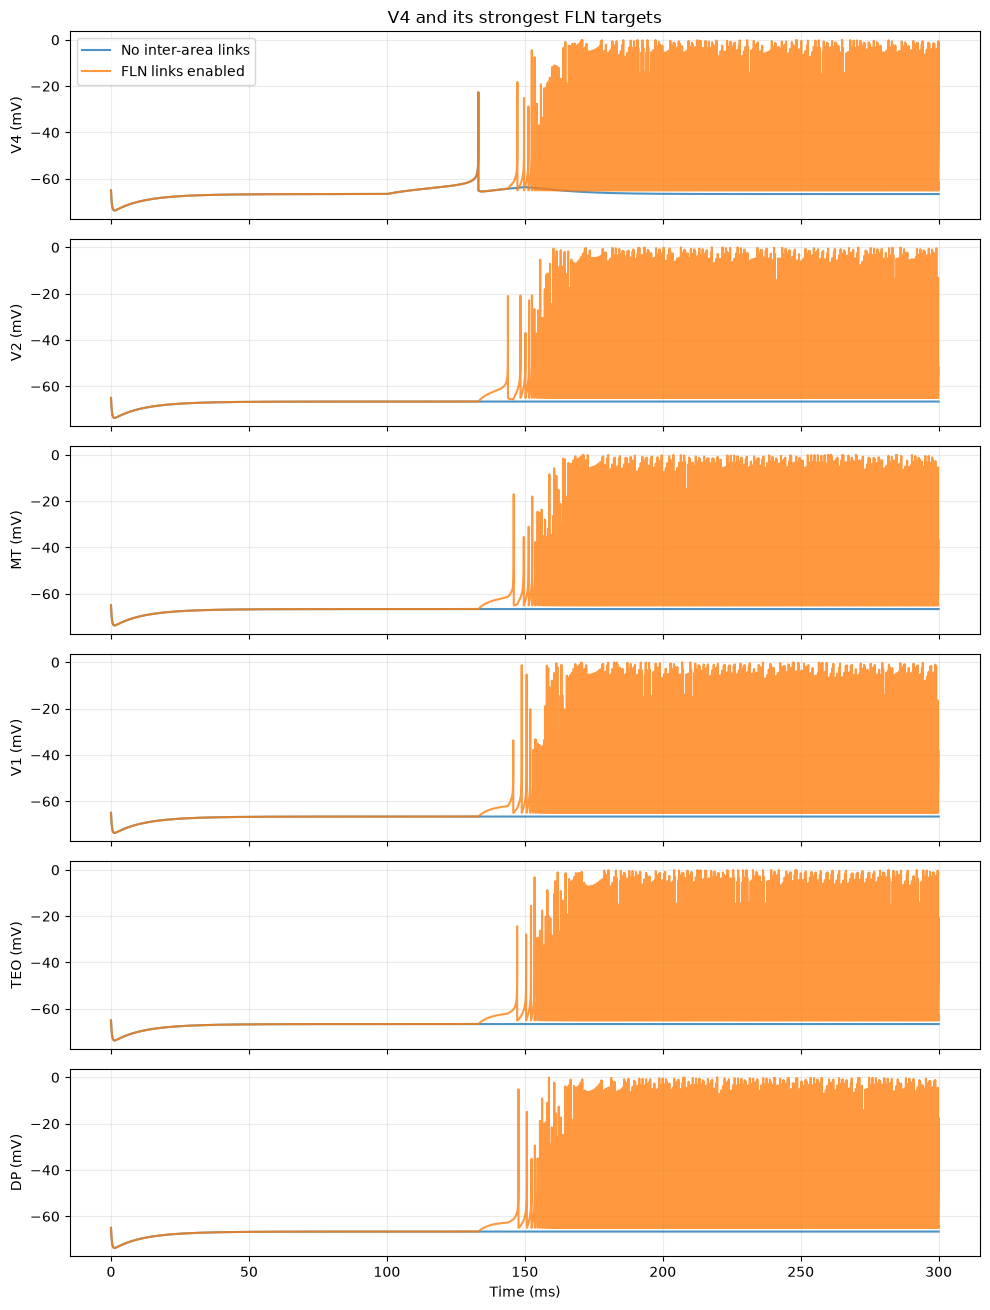

V4 outgoing targets:
  V4 -> V2: weight=0.2139
  V4 -> MT: weight=0.1908
  V4 -> V1: weight=0.1800
  V4 -> TEO: weight=0.1796
  V4 -> DP: weight=0.1645


In [7]:
v4_index = area_labels.index("V4")
v4_outgoing = fln_weights[:, v4_index].copy()
v4_outgoing[v4_index] = 0.0
target_order = np.argsort(v4_outgoing)[::-1]
target_indices = [i for i in target_order if v4_outgoing[i] > 0][:5]
areas_to_plot = [v4_index] + target_indices

fig, axes = plt.subplots(len(areas_to_plot), 1, figsize=(10, 2.2 * len(areas_to_plot)), sharex=True)
if len(areas_to_plot) == 1:
    axes = [axes]
for ax, area_idx in zip(axes, areas_to_plot):
    ax.plot(uncoupled["time_ms"], uncoupled["voltage_mv"][:, area_idx],
            label="No inter-area links", alpha=0.8)
    ax.plot(connected["time_ms"], connected["voltage_mv"][:, area_idx],
            label="FLN links enabled", alpha=0.8)
    ax.set_ylabel(f"{area_labels[area_idx]} (mV)")
    ax.grid(alpha=0.25)
axes[0].legend()
axes[0].set_title("V4 and its strongest FLN targets")
axes[-1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

print("V4 outgoing targets:")
for area_idx in target_indices:
    print(f"  V4 -> {area_labels[area_idx]}: weight={v4_outgoing[area_idx]:.4f}")

## Step 8: Compare spike propagation

Each row is one RTM cell. Compare the two conditions to see whether activity reaches areas connected to V4. The model has no conduction delays, so spike timing does not represent biological travel time.

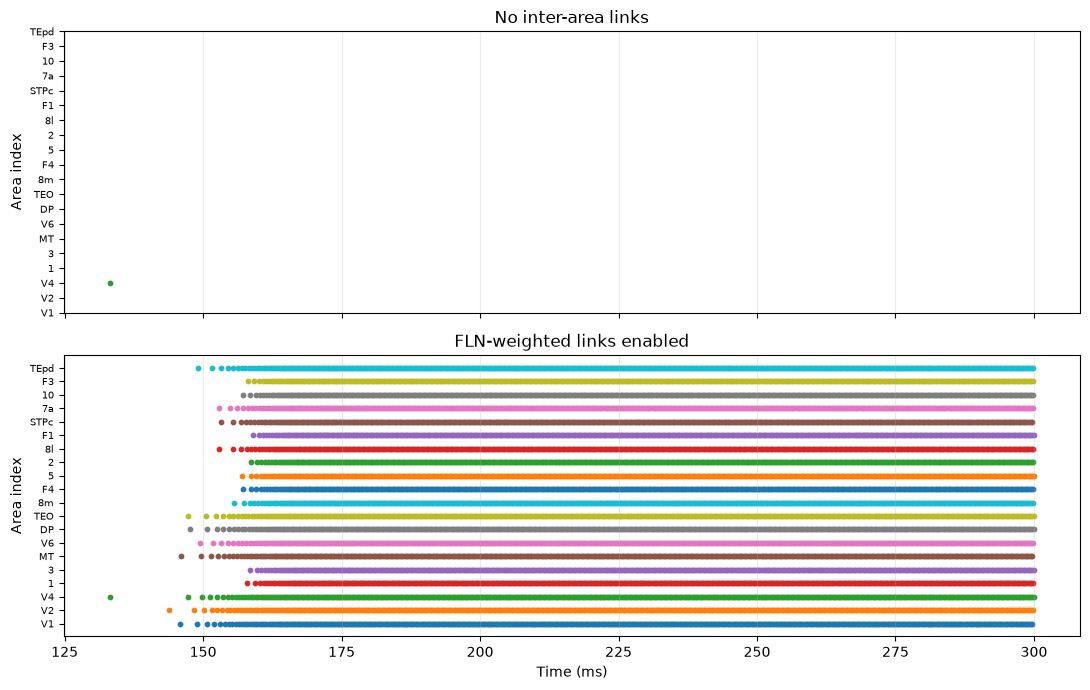

In [8]:
n_show = min(20, n_areas)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for area_idx in range(n_show):
    axes[0].scatter(
        uncoupled["spike_times_by_area"][area_idx],
        np.full(len(uncoupled["spike_times_by_area"][area_idx]), area_idx),
        s=10,
    )
    axes[1].scatter(
        connected["spike_times_by_area"][area_idx],
        np.full(len(connected["spike_times_by_area"][area_idx]), area_idx),
        s=10,
    )
axes[0].set_title("No inter-area links")
axes[1].set_title("FLN-weighted links enabled")
axes[1].set_xlabel("Time (ms)")
for ax in axes:
    ax.set_ylabel("Area index")
    ax.set_yticks(range(n_show))
    ax.set_yticklabels(area_labels[:n_show], fontsize=7)
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## How to read the result

- The uncoupled run is the control: V4 is stimulated, but its spikes cannot reach other areas.
- The connected run lets each source RTM spike deliver excitatory conductance to target RTM cells.
- FLN supplies direction and relative weight; link_conductance sets the overall scale.
- One RTM cell represents each area, so FLN acts as an effective area-to-area weight, not a literal count of synapses.
- This notebook omits WB cells, inter-area delays, noise, and multi-neuron populations.
- Pulse amplitude, conductance scale, and current units are provisional. Interpret the result after inspecting voltages and spike counts; change one parameter at a time.